In [2]:
import pandas as pd
from sqlalchemy import create_engine

# Below we specify the parameters required to access the db
host = "localhost"
user = "root"
password = ""
database = "milk_collection_db"

# create a connection to the dd
connection = f"mysql+pymysql://{user}:{password}@{host}/{database}"

# By use of sqlalchemy engine establish the connection
engine = create_engine(connection)

# specify the query you want to execute
query = """SELECT f.first_name AS farmer_first_name, f.last_name as farmer_last_name, p.amount, p.payment_date, p.status,c.litres * c.price_per_litre as Exact_amout_paid, c.litres, c.price_per_litre, po.first_name AS porter_first_name, po.last_name as porter_last_name FROM  farmers f 
INNER JOIN payments p ON f.farmer_id = p.farmer_id 
INNER JOIN collections c ON f.farmer_id = c.farmer_id
INNER JOIN porters po ON c.porter_id = po.porter_id;"""

# create a dataframe after the query has executed.
df = pd.read_sql_query(query, engine)

# print out the dataframe
df

,farmer_first_name,farmer_last_name,amount,payment_date,status,Exact_amout_paid,litres,price_per_litre,porter_first_name,porter_last_name
0,John,Kamau,5730.0,2026-06-05,PAID,2730.0,45.5,60.0,Samuel,Kiprotich
1,John,Kamau,5730.0,2026-06-05,PAID,3000.0,50.0,60.0,Samuel,Kiprotich
2,Mary,Wanjiku,4800.0,2026-06-05,PAID,2280.0,38.0,60.0,Samuel,Kiprotich
3,Mary,Wanjiku,4800.0,2026-06-05,PAID,2520.0,42.0,60.0,Samuel,Kiprotich
4,Peter,Kiptoo,6600.0,2026-06-05,PAID,3120.0,52.0,60.0,Brian,Mwangi
5,Peter,Kiptoo,6600.0,2026-06-05,PAID,3480.0,58.0,60.0,Brian,Mwangi
6,James,Mwangi,4830.0,2026-06-05,PAID,2490.0,41.5,60.0,Brian,Mwangi
7,James,Mwangi,4830.0,2026-06-05,PAID,2340.0,39.0,60.0,Brian,Mwangi
8,Grace,Njeri,7380.0,2026-06-05,PAID,3600.0,60.0,60.0,Kevin,Mutiso
9,Grace,Njeri,7380.0,2026-06-05,PAID,3780.0,63.0,60.0,Kevin,Mutiso


In [3]:
# finding the shape of our dafaframe
df.shape

(21, 10)

In [4]:
# check for some info in regards to the generated dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   farmer_first_name  21 non-null     str    
 1   farmer_last_name   21 non-null     str    
 2   amount             21 non-null     float64
 3   payment_date       21 non-null     object 
 4   status             21 non-null     str    
 5   Exact_amout_paid   21 non-null     float64
 6   litres             21 non-null     float64
 7   price_per_litre    21 non-null     float64
 8   porter_first_name  21 non-null     str    
 9   porter_last_name   21 non-null     str    
dtypes: float64(4), object(1), str(5)
memory usage: 1.8+ KB


In [5]:
# summary statistics for numeric columns
df.describe()

,amount,Exact_amout_paid,litres,price_per_litre
count,21.000000,21.000000,21.000000,21.000000
mean,6011.428571,2946.666667,50.500000,58.809524
std,1108.518316,553.446776,10.072239,5.455447
min,4350.000000,2100.000000,35.000000,35.000000
25%,4830.000000,2490.000000,42.000000,60.000000
50%,5970.000000,2910.000000,50.000000,60.000000
75%,6720.000000,3420.000000,58.000000,60.000000
max,7620.000000,3900.000000,70.000000,60.000000


In [6]:
# Below is how we export the entire dataframe into a csv
df.to_csv("milk_collection_data.csv", index=False)

In [7]:
# create a database table from an existing dataframe
df.to_sql("collection_summary", engine, if_exists="replace", index=False)

21

In [13]:
# check missing and duplicate values.
print(df.isnull().sum())
print("Duplicate rows: ", df.duplicated().sum())

farmer_first_name    0
farmer_last_name     0
amount               0
payment_date         0
status               0
Exact_amout_paid     0
litres               0
price_per_litre      0
porter_first_name    0
porter_last_name     0
dtype: int64
Duplicate rows:  0


In [24]:
# Clean up and create helper columns
# fix the column name typo, build full names and convert the date column.
df = df.rename(columns={"Exact_amount_paid" : "exact_amount"})
df["farmer"] = df["farmer_first_name"] + " " + df["farmer_last_name"]
df["porter"] = df["porter_first_name"] + " " + df["porter_last_name"]
df["payment_date"] = pd.to_datetime(df["payment_date"])
df

,farmer_first_name,farmer_last_name,amount,payment_date,status,Exact_amout_paid,litres,price_per_litre,porter_first_name,porter_last_name,farmer,porter
0,John,Kamau,5730.0,2026-06-05,PAID,2730.0,45.5,60.0,Samuel,Kiprotich,John Kamau,Samuel Kiprotich
1,John,Kamau,5730.0,2026-06-05,PAID,3000.0,50.0,60.0,Samuel,Kiprotich,John Kamau,Samuel Kiprotich
2,Mary,Wanjiku,4800.0,2026-06-05,PAID,2280.0,38.0,60.0,Samuel,Kiprotich,Mary Wanjiku,Samuel Kiprotich
3,Mary,Wanjiku,4800.0,2026-06-05,PAID,2520.0,42.0,60.0,Samuel,Kiprotich,Mary Wanjiku,Samuel Kiprotich
4,Peter,Kiptoo,6600.0,2026-06-05,PAID,3120.0,52.0,60.0,Brian,Mwangi,Peter Kiptoo,Brian Mwangi
5,Peter,Kiptoo,6600.0,2026-06-05,PAID,3480.0,58.0,60.0,Brian,Mwangi,Peter Kiptoo,Brian Mwangi
6,James,Mwangi,4830.0,2026-06-05,PAID,2490.0,41.5,60.0,Brian,Mwangi,James Mwangi,Brian Mwangi
7,James,Mwangi,4830.0,2026-06-05,PAID,2340.0,39.0,60.0,Brian,Mwangi,James Mwangi,Brian Mwangi
8,Grace,Njeri,7380.0,2026-06-05,PAID,3600.0,60.0,60.0,Kevin,Mutiso,Grace Njeri,Kevin Mutiso
9,Grace,Njeri,7380.0,2026-06-05,PAID,3780.0,63.0,60.0,Kevin,Mutiso,Grace Njeri,Kevin Mutiso


In [23]:
# Understand what one row means.
# Each row is one collection, but amount(the payment) is repeated on every row for the same farmer. Check how many different payments value each farmer has.
df.groupby("farmer").agg(
    collections=("litres", "size"),
    distint_payment_values=("amount", "nunique"),
    payment_dates=("payment_date", "nunique"),
)

,collections,distint_payment_values,payment_dates
farmer,,,
Daniel Koech,2,1,1
David Mutua,2,1,1
Faith Chebet,2,1,1
Grace Njeri,3,1,1
James Mwangi,2,1,1
John Kamau,2,1,1
Joseph Maina,2,1,1
Mary Wanjiku,2,1,1
Peter Kiptoo,2,1,1


In [26]:
# the sum of the amount that was paid to the farmers wrongly against the sum of the correct amount that was to be paid to the farmer
payments = df.drop_duplicates(subset=["farmer", "amount"])[["farmer", "amount", "payment_date"]]
print("total amount paid: ", payments["amount"].sum())
print("wrong total if you sum the amount: ", df["amount"].sum())
print("The difference of the figures is: ", df["amount"].sum() - payments["amount"].sum())

total amount paid:  59430.0
wrong total if you sum the amount:  126240.0
The difference of the figures is:  66810.0


In [ ]:
# number of collection handled by each and every porter
df.groupby("porter_first_name").size()

porter_first_name
Brian     4
Dennis    4
Kevin     5
Samuel    4
Victor    4
dtype: int64

C:\Users\Ben\AppData\Local\Temp\ipykernel_16584\1142319972.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='porter', data = df, palette="spring")


Text(0.5, 0, 'Name of the porter')

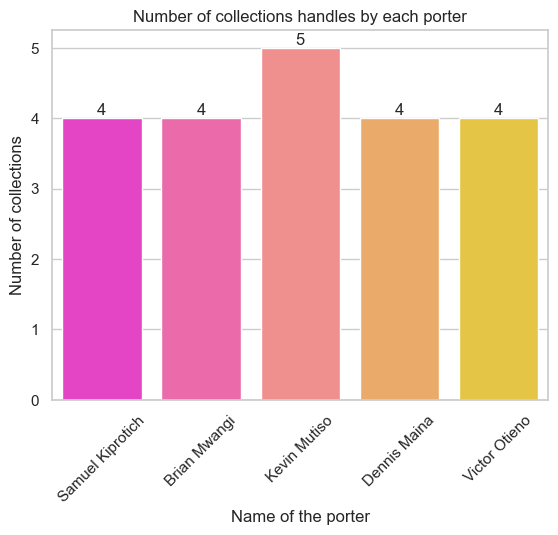

In [47]:
# The above info can be presented on a countplot as show below
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

ax = sns.countplot(x='porter', data = df, palette="spring")

# below we give the exact number for each bar
for container in ax.containers:
    ax.bar_label(container)

# Below we are rotating the names so that they do not overlap each other.
plt.xticks(rotation=45)
plt.title("Number of collections handles by each porter")
plt.ylabel("Number of collections")
plt.xlabel("Name of the porter")

In [37]:
# number of collection that happened to each farmer
df.groupby("farmer_first_name").size()

farmer_first_name
Daniel    2
David     2
Faith     2
Grace     3
James     2
John      2
Joseph    2
Mary      2
Peter     2
Susan     2
dtype: int64

C:\Users\Ben\AppData\Local\Temp\ipykernel_16584\3798374262.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(y='farmer', data = df, palette="autumn")


Text(0.5, 0, 'Number of Collections')

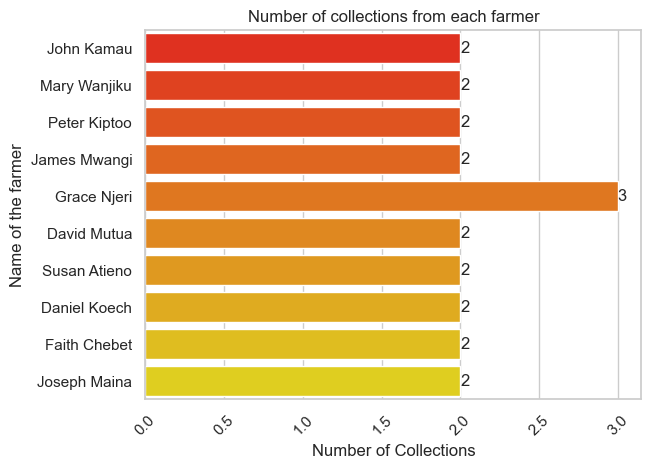

In [48]:
# Have a visual of the number of collections that happened to each farmer.
ax = sns.countplot(y='farmer', data = df, palette="autumn")

# below we give the exact number for each bar
for container in ax.containers:
    ax.bar_label(container)

# Below we are rotating the names so that they do not overlap each other.
plt.xticks(rotation=45)
plt.title("Number of collections from each farmer")
plt.ylabel("Name of the farmer")
plt.xlabel("Number of Collections")

Text(0, 0.5, 'Total count')

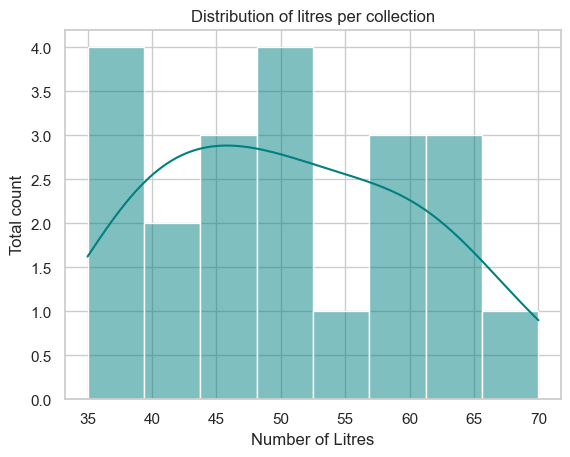

In [49]:
# Distribution of litres per collection
sns.histplot(df["litres"], bins=8, kde=True, color="teal")
plt.title("Distribution of litres per collection")
plt.xlabel("Number of Litres")
plt.ylabel("Total count")

Text(0.5, 1.0, 'Share of litres collected by each porter')

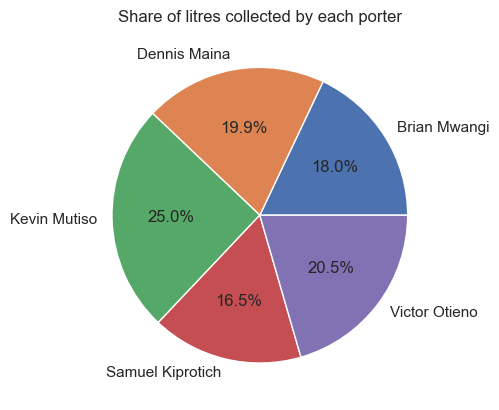

In [51]:
# visualize what each and every porter was able to deliver using a piechart
df.groupby("porter")["litres"].sum().plot.pie(autopct="%1.1f%%")
plt.title("Share of litres collected by each porter")

Text(0.5, 1.0, 'percentage of litres supplied by a farmer')

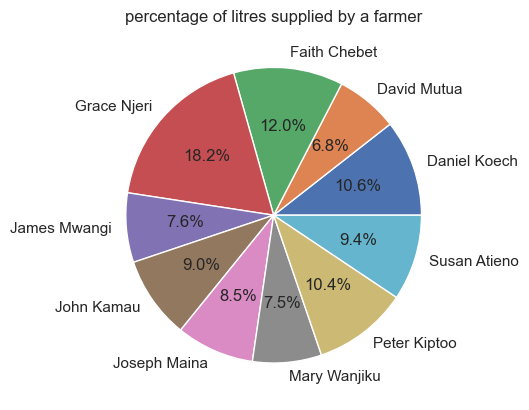

In [55]:
# visualize how many litres each and every farmer was able to deliver using a piechart
df.groupby("farmer")["litres"].sum().plot.pie(autopct="%1.1f%%")
plt.title("percentage of litres supplied by a farmer")

C:\Users\Ben\AppData\Local\Temp\ipykernel_16584\2957618819.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="litres", y="farmer", data = farmer_litres, palette="spring")


Text(0, 0.5, "Farmer's Name")

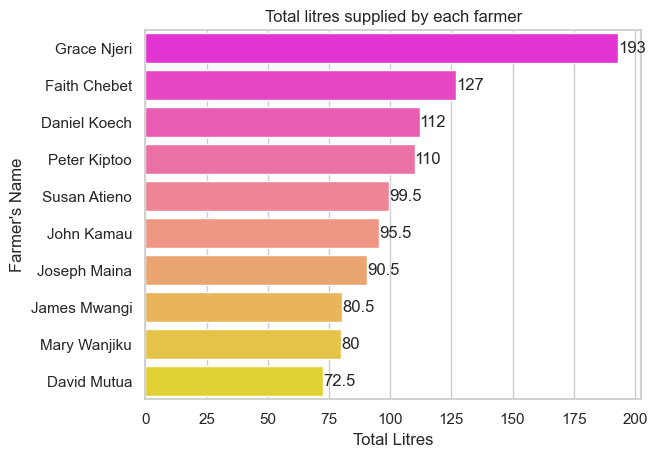

In [60]:
# Total litres supplied by each farmer
farmer_litres = df.groupby("farmer")["litres"].sum().sort_values(ascending =False).reset_index()

ax = sns.barplot(x="litres", y="farmer", data = farmer_litres, palette="spring")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Total litres supplied by each farmer")
plt.xlabel("Total Litres")
plt.ylabel("Farmer's Name")